<a href="https://colab.research.google.com/github/sessm216/Finphysics/blob/main/Montecarlo_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
"""
Created on Thu Aug  13 20:24:03 2026

@author: sanch

Nota: revisar plots.
"""

'\nCreated on Thu Aug  13 20:24:03 2026\n\n@author: sanch\n\nNota: revisar plots. \n'

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
#Condiciones de contorno
# ---------------------------------------------------------------
np.random.seed(42)

capital_inicial = 10_000
anios = 10
dias_por_anio = 252           # días de mercado abiertos al año
n_simulaciones = 5_000


activos = ["tech", "bank", "comm"]
pesos = np.array([0.50, 0.30, 0.20])
rend_anual = np.array([0.10, 0.07, 0.06])          # μ
vol_anual = np.array([0.30, 0.22, 0.15])           # σ

#Correlation matrix
correlaciones = np.array([
    [1.0, 0.5, 0.3],
    [0.5, 1.0, 0.4],
    [0.3, 0.4, 1.0],
])


n_pasos = anios * dias_por_anio
dt = 1 / dias_por_anio        #paso
n_activos = len(activos)

# Matriz de covarianzas a partir de volatilidades y correlaciones
covarianzas = np.outer(vol_anual, vol_anual) * correlaciones

# Cholesky: todavia tengo que entender que es
L = np.linalg.cholesky(correlaciones)


#Sim

inversion_inicial = capital_inicial * pesos


valor_portfolio = np.zeros((n_simulaciones, n_pasos + 1))
valor_portfolio[:, 0] = capital_inicial

for sim in range(n_simulaciones):
    valores = inversion_inicial.copy()

    for t in range(1, n_pasos + 1):
        z = np.random.normal(size=n_activos)
        z_corr = L @ z
        # Movimiento browniano geométrico
        retorno_log = (rend_anual - 0.5 * vol_anual**2) * dt \
                      + vol_anual * np.sqrt(dt) * z_corr
        valores = valores * np.exp(retorno_log)

        valor_portfolio[sim, t] = valores.sum()


valores_finales = valor_portfolio[:, -1]

media = valores_finales.mean()
mediana = np.median(valores_finales)
p5 = np.percentile(valores_finales, 5)     # escenario pesimista
p95 = np.percentile(valores_finales, 95)   # escenario optimista

### Parte de VaR: revisar conceptualmente
#
var_95 = max(0, capital_inicial - p5)

peores = valores_finales[valores_finales <= p5]
cvar_95 = max(0, capital_inicial - peores.mean())

prob_perder = (valores_finales < capital_inicial).mean() * 100
prob_duplicar = (valores_finales > 2 * capital_inicial).mean() * 100

print(f"\n=== Resultados tras {anios} años ({n_simulaciones} simulaciones) ===")
print(f"Capital inicial:          {capital_inicial:>10,.0f} €")
print(f"Valor medio final:        {media:>10,.0f} €")
print(f"Valor mediano final:      {mediana:>10,.0f} €")
print(f"Escenario pesimista (P5): {p5:>10,.0f} €")
print(f"Escenario optimista (P95):{p95:>10,.0f} €")
print(f"VaR 95%:                  {var_95:>10,.0f} €")
print(f"CVaR 95%:                 {cvar_95:>10,.0f} €")
print(f"Probabilidad de perder dinero:  {prob_perder:.1f}%")
print(f"Probabilidad de duplicar:       {prob_duplicar:.1f}%")



=== Resultados tras 10 años (5000 simulaciones) ===
Capital inicial:              10,000 €
Valor medio final:            23,342 €
Valor mediano final:          18,104 €
Escenario pesimista (P5):      6,676 €
Escenario optimista (P95):    57,811 €
VaR 95%:                       3,324 €
CVaR 95%:                      4,531 €
Probabilidad de perder dinero:  17.1%
Probabilidad de duplicar:       43.3%


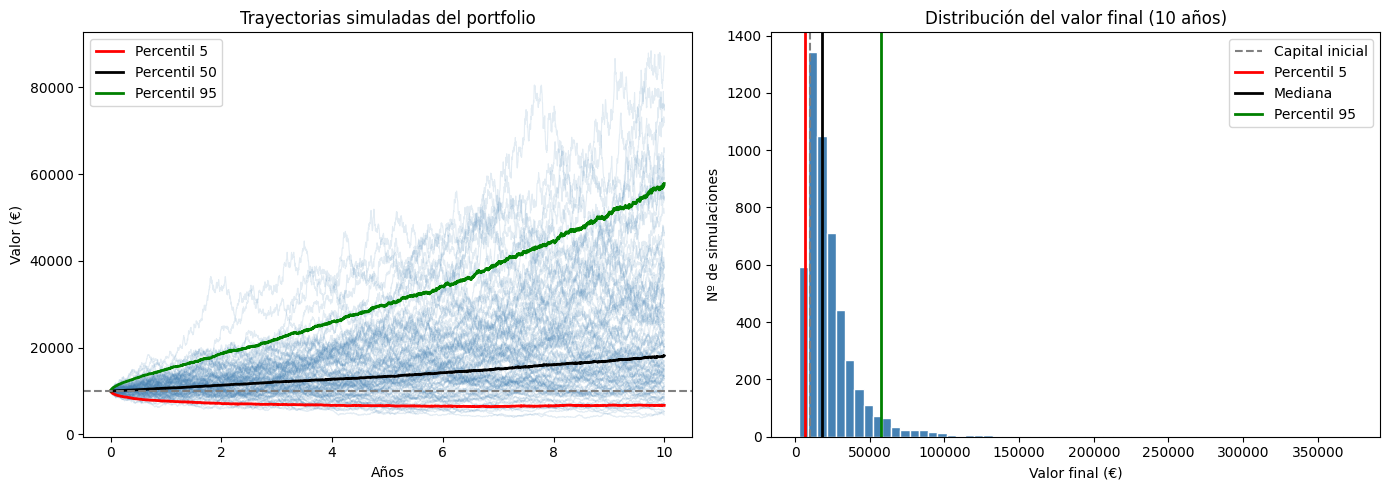

In [6]:



# Plotear
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

eje_anios = np.linspace(0, anios, n_pasos + 1)
for i in range(100):                        # dibujamos solo 100 para no saturar
    ax1.plot(eje_anios, valor_portfolio[i], color="steelblue", alpha=0.15, lw=0.8)
for p, color in [(5, "red"), (50, "black"), (95, "green")]:
    ax1.plot(eje_anios, np.percentile(valor_portfolio, p, axis=0),
             color=color, lw=2, label=f"Percentil {p}")
ax1.axhline(capital_inicial, color="gray", ls="--")
ax1.set_title("Trayectorias simuladas del portfolio")
ax1.set_xlabel("Años")
ax1.set_ylabel("Valor (€)")
ax1.legend()


ax2.hist(valores_finales, bins=60, color="steelblue", edgecolor="white")
ax2.axvline(capital_inicial, color="gray", ls="--", label="Capital inicial")
ax2.axvline(p5, color="red", lw=2, label="Percentil 5")
ax2.axvline(mediana, color="black", lw=2, label="Mediana")
ax2.axvline(p95, color="green", lw=2, label="Percentil 95")
ax2.set_title(f"Distribución del valor final ({anios} años)")
ax2.set_xlabel("Valor final (€)")
ax2.set_ylabel("Nº de simulaciones")
ax2.legend()

plt.tight_layout()
plt.savefig("montecarlo_resultado.png", dpi=120)
plt.show()

Preguntas:


*   Interpretar VaR
*   Otros datos
*   Algoritmo Metrópolis? Implementar optimización -> probar código en C++

